In [3]:
import torch
import torch.nn as nn
import torchvision
import torchvision.datasets as datasets
import random

import torchvision.transforms as transforms
from torchvision.transforms import v2
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset
from torch.utils.data import random_split
    
import numpy as np 
%matplotlib inline
import matplotlib.pyplot as plt 

import itertools
import pandas as pd

# Downloading data 

Run the code block below to download all the data you need for task 1 and 2 (took me like 20 minutes for the CIFAR10 datasets, but the other ones were pretty quick)

To (un)comment multiple lines: CTRL + /

Please leave it uncommented after using, so we don't have to download all the data again when we rerun the notebook

In [ ]:
# # Download the CIFAR datasets
# cifar10_train = datasets.CIFAR10(root = "./data", train = True, download = True)
# cifar10_test = datasets.CIFAR10(root = "./data", train = False, download = True)

# # Download Fashion-MNIST datasets
# fashion_train = datasets.FashionMNIST(root = "./data", train = True, download = True)
# fashion_test = datasets.FashionMNIST(root = "./data", train = False, download = True)

# # Download time datasets (Task 2)
# import os
# from urllib.request import urlretrieve
# import zipfile

# urls = ["https://surfdrive.surf.nl/public.php/dav/files/Nznt5c48Mzlb2HY/A1_data_75.zip", 
#         "https://surfdrive.surf.nl/public.php/dav/files/Nznt5c48Mzlb2HY/A1_data_150.zip"]

# target_folder = "./data"

# for url in urls:
#     file_name = os.path.basename(url)
#     full_path = os.path.join(target_folder, file_name)

#     # Create separate folder for each dataset 
#     dataset_name = os.path.splitext(file_name)[0]
#     extract_folder = os.path.join(target_folder, dataset_name)
#     os.makedirs(extract_folder, exist_ok = True)

#     # Download zip file
#     urlretrieve(url, full_path)

#     # Extract zip file
#     with zipfile.ZipFile(full_path, "r") as zip_ref:
#         zip_ref.extractall(extract_folder)

#     # Remove ZIP file
#     os.remove(full_path)

# Task 1

## Fashion MNIST

### Processing

**Loading data: train, validation, test**

In [1]:
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
fashion_train_all = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

fashion_test = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

# Split 10% of training data for the validation set
train_size = int(0.9 * len(fashion_train_all))
validation_size = len(fashion_train_all) - train_size

fashion_train, fashion_validation = random_split(
    fashion_train_all,
    [train_size, validation_size],
    generator = torch.Generator().manual_seed(67) # (our group number)
)

NameError: name 'v2' is not defined

**Visualise**

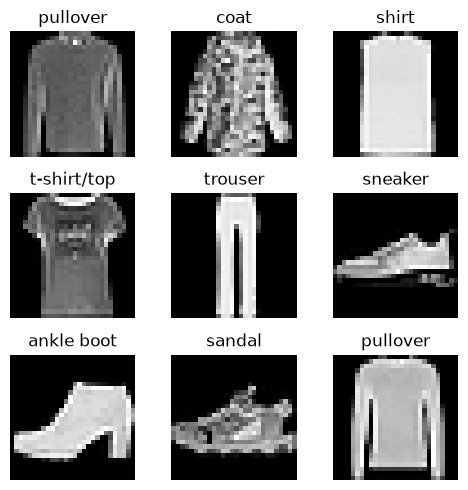

In [4]:
# Define class names
fashion_names = {
    0: "t-shirt/top",
    1: "trouser",
    2: "pullover",
    3: "dress",
    4: "coat",
    5: "sandal",
    6: "shirt",
    7: "sneaker",
    8: "bag",
    9: "ankle boot"
}

# Visualise 
n = 3

fig, ax = plt.subplots(n, n, figsize = (5, 5))

for i in range(n):
    for j in range(n):
        image, label = fashion_train[i * n + j] 
        image_np = image.numpy().squeeze() # Convert image tensor to numpy array
        ax[i, j].imshow(image_np, cmap = "gray")
        ax[i, j].axis("off")
        ax[i, j].set_title(fashion_names[label])
plt.tight_layout()
plt.show()

**Dataloader** (for more efficient processing)

Shuffling doesn't really matter for the validation and test set. Only changes the order of things, but if you take the average it should be the same regardless of order

In [5]:
batch_size = 64

fashion_train_loader = DataLoader(fashion_train, batch_size = batch_size, shuffle = True)
fashion_validation_loader = DataLoader(fashion_validation, batch_size = batch_size, shuffle = False)
fashion_test_loader = DataLoader(fashion_test, batch_size = batch_size, shuffle = False)

In [6]:
print(f"Number of batches in the training DataLoader: {len(fashion_train_loader)}")
print(f"Number of batches in the validation DataLoader: {len(fashion_validation_loader)}")
print(f"Number of batches in the test DataLoader: {len(fashion_test_loader)}")
images, labels = next(iter(fashion_train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Pixel range:", images.min().item(), images.max().item())

Number of batches in the training DataLoader: 844
Number of batches in the validation DataLoader: 94
Number of batches in the test DataLoader: 157
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Image data type: torch.float32
Pixel range: 0.0 1.0


### Model building

NOTES
* The amount of hidden layers and nodes I choose for them feels rather arbitrary. I just followed along with the values from the tutorial but idk if there would be a good reasoning for it

In [7]:
# Hardware device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [8]:
# Class to create a neural network
class NeuralNetwork(nn.Module):
    def __init__(self, 
            model_type = "MLP", # type of model to create (MLP or CNN)
            in_channels = 1, # number of input channels (1 for grayscale images)
            image_size = 28, # size of the input image (28x28 for FashionMNIST)
            hidden_dims = [128, 64], # list of hidden dimensions for MLP
            cnn_channels = [16, 32], # list of convolutional channels for CNN
            kernel_size=3, #size of the convolutional kernel for CNN
            pool_size=2, #size of the pooling kernel for CNN
            stride=2, #stride for pooling for CNN
            activation=nn.ReLU, #activation function
            initialization=None, #weight initialization method
            dropout=0.0 #dropout rate
            ):   
         
        super().__init__() 
        self.model_type = model_type

        #---------------Build the MLP model---------------
        if model_type == "MLP":
            # Create the layers 
            layers = [nn.Flatten()]
            input_size = in_channels * image_size * image_size # Amount of pixels we have

            for hidden_size in hidden_dims:
                layers.append(nn.Linear(input_size, hidden_size))
                layers.append(activation())

                if dropout > 0:
                    layers.append(nn.Dropout(dropout))

                input_size = hidden_size # Change input size, so each layer connects to the next one

            layers.append(nn.Linear(input_size, 10)) # Last layer (output: 10, because we have 10 classes)

            # Combine all our layers into a network
            self.network = nn.Sequential(*layers)# asterisk transforms the list into positional arguments

        #---------------Build the CNN model---------------
        elif model_type == "CNN":
            # Convolutional layers
            feature_layers = []
            current_size = image_size
            for conv_block in range(len(cnn_channels)): # we iterate over the number of convolutional blocks
                in_ch = in_channels if conv_block == 0 else cnn_channels[conv_block - 1]#if conv_block == 0, we use the input channels, otherwise we use the output channels of the previous layer
                out_ch = cnn_channels[conv_block]
                
                feature_layers.append(nn.Conv2d(in_ch, out_ch, kernel_size, padding=kernel_size // 2))# We use padding to keep the output size the same as the input size
                feature_layers.append(activation())
                feature_layers.append(nn.MaxPool2d(kernel_size=pool_size, stride=stride))# We use max pooling to reduce the size of the feature maps
                if dropout > 0:
                    feature_layers.append(nn.Dropout(dropout))

                # MaxPool2d reduces spatial size by stride factor
                current_size = current_size // stride
            # Combine all our layers into a feature extractor
            self.features = nn.Sequential(*feature_layers)

            #Linear Layers
            classifier_layers = [nn.Flatten()]
            input_size = cnn_channels[-1] * current_size * current_size # Last convolutional layer output channels * spatial size of the feature maps
            for hidden_size in hidden_dims:
                classifier_layers.append(nn.Linear(input_size, hidden_size))
                classifier_layers.append(activation())
            
                if dropout > 0:
                    classifier_layers.append(nn.Dropout(dropout))
            
                input_size = hidden_size   

            classifier_layers.append(nn.Linear(input_size, 10)) # Last layer (output: 10, because we have 10 classes)
            # Combine all our layers into a classifier
            self.classifier = nn.Sequential(*classifier_layers)

        # Initialize weights
        if initialization is not None: # Doublecheck that Initilization = None in the baseline model is what the lecturer explained in class
            self.parameter_initializations(initialization)

    def forward(self, x):
        if self.model_type == "MLP":
            return self.network(x)

        elif self.model_type == "CNN":
            x = self.features(x)
            logits = self.classifier(x)
            return logits

    def parameter_initializations(self, name):

        for layer in self.modules():
            if isinstance(layer, (nn.Linear, nn.Conv2d)):

                match name:
                    case "uniform": 
                        nn.init.uniform_(layer.weight)
                    case "xavier":
                        nn.init.xavier_uniform_(layer.weight)
                    case "kaiming":
                        nn.init.kaiming_uniform_(layer.weight, a = 0, mode = "fan_in", nonlinearity = "relu")
                    case "zero": 
                        nn.init.zeros_(layer.weight)
                    case "one":
                        nn.init.ones_(layer.weight)
                    case "normal":
                        nn.init.normal_(layer.weight, mean = 0.0, std = 1)

        
    def create_optimizer(self, name, learning_rate, weight_decay, momentum): # Possibly redundant, see below in def run_experiment.
        optimizer_name = {
            "SGD": optim.SGD,
            "Adam": optim.Adam,
            "AdamW": optim.AdamW
        }

        args = {"lr": learning_rate, "weight_decay": weight_decay}

        if name == "SGD": 
            args["momentum"] = momentum

        # Return the optimizer
        return optimizer_name[name](self.parameters(), **args)


In [ ]:
def count_parameters(model, verbose=True):
    total_params = sum(p.numel() for p in model.parameters())
    if verbose:
        print(f"Total Parameters: {total_params:,}")
    return total_params

In [9]:
criterion = nn.CrossEntropyLoss()

def run_experiment(params, train = fashion_train, validation = fashion_validation, 
                   test = fashion_test, plotting = False, seed = 67):
    # 1. Force identical random states for experimental runs (for reproducibility).
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    
    # Create DataLoaders
    train_loader = DataLoader(train, batch_size = params["batch_size"], shuffle = True)
    validation_loader = DataLoader(validation, batch_size = params["batch_size"], shuffle = False)
    test_loader = DataLoader(test, batch_size = params["batch_size"], shuffle = False)

    # Create the model
    model_params = {key: value for key, value in params.items() 
                    if key not in ("epochs", "batch_size", "optimizer", 
                                   "learning_rate", "momentum", "weight_decay")}
    model = NeuralNetwork(**model_params).to(device)

    # Create optimizer, possibly redundant? We create the optimizer here but also have a class function for it, remove one of two.
    optimizer_name = {
        "SGD": optim.SGD,
        "Adam": optim.Adam,
        "AdamW": optim.AdamW
    }

    args = {"lr": params["learning_rate"], "weight_decay": params["weight_decay"]}

    if params["optimizer"] == "SGD": 
        args["momentum"] = params["momentum"]

    optimizer = optimizer_name[params["optimizer"]](model.parameters(), **args)

    # Store losses and accuracies for each epoch
    history = {
        "train_loss": [0.0] * params["epochs"],
        "val_loss": [0.0] * params["epochs"],
        "train_acc": [0.0] * params["epochs"],
        "val_acc": [0.0] * params["epochs"]
        }

    best_val_loss = np.inf
    best_model_state = None

    for epoch in range(params["epochs"]):
        model.train()


        #---------- Training Phase ----------
        train_loss_total = 0.0
        train_correct_total = 0
        train_total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad() 
            
            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # Backward pass 
            loss.backward()
            optimizer.step()

            # Training performance
            train_loss_total += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs.data, 1) # Get the index of the max log-probability
            train_correct_total += (predicted == labels).sum().item() # Count the number of correct predictions
            train_total += labels.size(0)

        # Average training loss for this epoch
        history["train_loss"][epoch] = train_loss_total / train_total

        # Average training accuracy for this epoch
        history["train_acc"][epoch] = 100.0 * train_correct_total / train_total

        #---------- Validation Phase ----------
        #Validate after each epoch
        model.eval()
        val_loss_total = 0.0
        val_correct_total = 0
        val_total = 0
        with torch.no_grad():
            for inputs, labels in validation_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss_total += loss.item() * labels.size(0)

                _, predicted = torch.max(outputs.data, 1)
                val_correct_total += (predicted == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_total / val_total        
        history["val_loss"][epoch] = val_loss
        history["val_acc"][epoch] = 100.0 * val_correct_total / val_total

        # Save model with lowest validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            # Saves model's parameters (cloning tensor onto CPU memory)
            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    # Get the best model
    model.load_state_dict(best_model_state)

    #---------- Test Phase ----------
    # Evaluate performance on unseen data (test set)
    test_loss_total = 0.0
    test_correct_total = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            test_loss_total += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs.data, 1)
            test_correct_total += (predicted == labels).sum().item()
            test_total += labels.size(0)

    test_loss = test_loss_total / test_total
    # Calculate test accuracy
    test_acc = 100.0 * test_correct_total / test_total

    history["test_acc"] = test_acc

    # Calculate best validation accuracy (from the epoch with lowest val loss)
    best_val_acc = history["val_acc"][np.argmin(history["val_loss"])]


    if plotting:
        epochs_range = range(1, params["epochs"] + 1)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

        # Loss Plot
        ax1.plot(epochs_range, history["train_loss"], marker="o", label="Train Loss")
        ax1.plot(epochs_range, history["val_loss"], marker="o", label="Validation Loss")
        ax1.set_title("Cross-Entropy Loss")
        ax1.set_xlabel("Epoch")
        ax1.set_ylabel("Loss")
        ax1.legend()
        ax1.grid(True) 

        # Accuracy Plot
        ax2.plot(epochs_range, history["train_acc"], marker="o", label="Train Accuracy")
        ax2.plot(epochs_range, history["val_acc"], marker="o", label="Validation Accuracy")
        ax2.set_title("Classification Accuracy (%)")
        ax2.set_xlabel("Epoch")
        ax2.set_ylabel("Accuracy (%)")
        ax2.legend()
        ax2.grid(True) 

        plt.tight_layout()
        plt.show()
    
    return model, history, best_val_loss, best_val_acc, test_loss, test_acc

## Parameters and Testing

Parameters

* Model and architecture
    * model_type: "MLP" or "CNN"
    * hidden_dims: Any list of descending integers
    * channels
    * kernel_size 
* Activation
    * Can be nn.ReLU, nn.LeakyReLU, nn.GELU
    * Also more options (see Session 3 slide 10) nn.Signmoid, nn.Tahn, nn.PReLU, nn.Softplus, nn.SiLU, nn.ELU, nn.SELU 
* Optimizer
    * optimizer: "SGD", "Adam", "AdamW"
    * learning_rate
    * momentum
* Regularization
    * dropout
* Training
    * epochs
    * batch_size


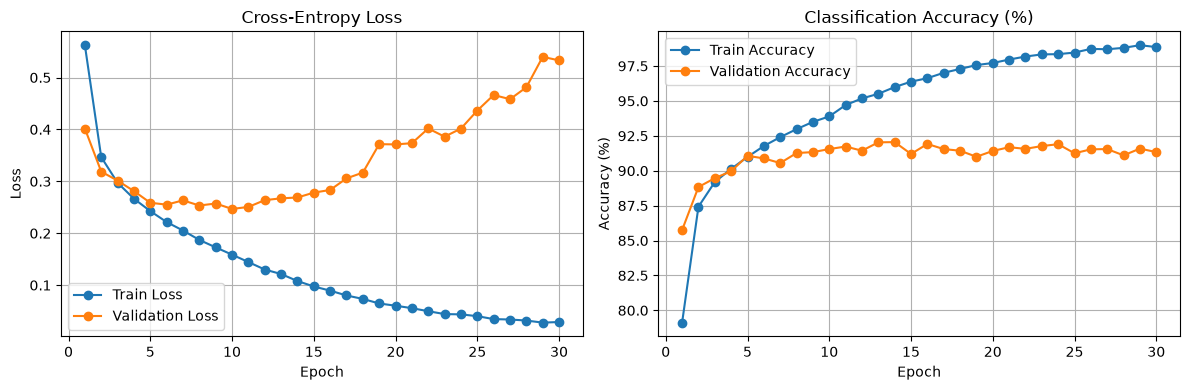


Experiment 1 Results:
NeuralNetwork(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
Best Validation Loss: 0.2468|Best Validation Accuracy: 91.55%
Test Loss: 0.2601 | Test Accuracy: 90.85%


In [11]:
params1 = {
    # Model and architecture
    "model_type": "CNN", # "MLP" or "CNN"
    "hidden_dims": [128, 64], 
    "cnn_channels": [16, 32], # Only for CNNs
    "kernel_size": 3, # Only for CNNs
    "pool_size": 2, # Only for CNNs
    "stride": 2, # Only for CNNs

    # Activation
    "activation": nn.ReLU, 

    # Weight initialization
    "initialization": None, # Optional

    # Optimizer
    "optimizer": "AdamW",
    "learning_rate": 0.001, 
    "weight_decay": 0.0, # Optional, regularization
    "momentum": 0.9, # Only if optimizer = "SGD"

    # Regularization
    "dropout": 0.0, # Optional

    # Training
    "epochs": 30,
    "batch_size": 64
}

model1, history1, best_val_loss1,best_val_acc1, test_loss1, test_acc1 = run_experiment(params1, plotting=True)

print("\nExperiment 1 Results:")
print(model1)
print(f"Best Validation Loss: {best_val_loss1:.4f}|Best Validation Accuracy: {best_val_acc1:.2f}%")
print(f"Test Loss: {test_loss1:.4f} | Test Accuracy: {test_acc1:.2f}%")

### We use parameter grids, in order to find the effect of each Hyperparameter

In [14]:
    # 1. Define base parameters that remain constant
    base_params = {
        "model_type": "CNN",
        "in_channels": 1,
        "image_size": 28,
        "hidden_dims": [128, 64],
        "activation": nn.ReLU,
        "initialization": None,
        "weight_decay": 0.0,
        "dropout": 0.0,
        "epochs": 15,      # We should keep epochs low during grid search to save time
        "batch_size": 64
    }

    # 2. Define the parameters you want to test
    lr_grid = {
        "SGD":   [0.1, 0.03, 0.01, 0.003, 0.001],
        "AdamW": [0.01, 0.003, 0.001, 0.0003, 0.0001],
    }
    experiment_results = []

    # 3. Loop through all possible combinations

    for opt, lrs in lr_grid.items():
        for lr in lrs:
            print(f"Testing -> Optimizer: {opt} | LR: {lr}")
        
            # Clone base params and inject the current test variables
            current_params = base_params.copy()
            current_params["learning_rate"] = lr
            current_params["optimizer"] = opt
        
            # Handle the momentum edge case (Adam doesn't use standard momentum)
            current_params["momentum"] = 0.9 if opt == "SGD" else 0.0
        

            # We set plotting = False to prevent plot generation.
            model, history, val_loss, val_acc, test_loss, test_acc = run_experiment(
            current_params, 
            plotting=False 
            )
        
            # We save the metrics
            experiment_results.append({
                "Optimizer": opt,
                "LR": lr,
                "Dropout": base_params["dropout"],
                "Val Loss": round(val_loss, 4),
                "Val Acc (%)": round(val_acc, 2),
                "Test Acc (%)": round(test_acc, 2)
            })

    # 4. Display the results neatly
    results_df = pd.DataFrame(experiment_results)
    # Sort by highest validation accuracy
    results_df = results_df.sort_values(by="Val Acc (%)", ascending=False).reset_index(drop=True)
    display(results_df)

Testing -> Optimizer: SGD | LR: 0.1
Testing -> Optimizer: SGD | LR: 0.03
Testing -> Optimizer: SGD | LR: 0.01
Testing -> Optimizer: SGD | LR: 0.003
Testing -> Optimizer: SGD | LR: 0.001
Testing -> Optimizer: AdamW | LR: 0.01
Testing -> Optimizer: AdamW | LR: 0.003
Testing -> Optimizer: AdamW | LR: 0.001
Testing -> Optimizer: AdamW | LR: 0.0003
Testing -> Optimizer: AdamW | LR: 0.0001


,Optimizer,LR,Dropout,Val Loss,Val Acc (%),Test Acc (%)
0,AdamW,0.0010,0.0,0.2467,91.98,91.60
1,SGD,0.0100,0.0,0.2395,91.67,91.23
2,AdamW,0.0030,0.0,0.2465,91.37,91.02
3,SGD,0.0300,0.0,0.2487,91.22,90.29
4,AdamW,0.0003,0.0,0.2596,90.92,90.30
5,AdamW,0.0100,0.0,0.2807,90.57,89.95
6,SGD,0.0030,0.0,0.2940,89.17,88.94
7,SGD,0.1000,0.0,0.3070,89.10,88.39
8,AdamW,0.0001,0.0,0.3281,88.90,88.05
9,SGD,0.0010,0.0,0.3479,87.55,87.20


In [ ]:
def sweep_one(base, name, values):
    # Vary one hyperparameter at a time, keep the rest constant
    rows = []
    for value in values:
        params = base.copy()
        params[name] = value

        model, history, val_loss, val_acc, test_loss, test_acc = run_experiment(params)

        rows.append({
            name: value.__name__ if isinstance(value, type) else value,  # shows ReLU instead of <class ...>
            "n_params": count_parameters(model, verbose=False),
            "val_loss": round(val_loss, 4),
            "val_acc": round(val_acc, 2),
        })

    return pd.DataFrame(rows).sort_values("val_acc", ascending=False).reset_index(drop=True)

In [ ]:
# Winner of stage 1: AdamW, lr 0.001
base = {**base_params, "optimizer": "AdamW", "learning_rate": 0.001, "momentum": 0.0}

In [ ]:
# Stage 2: Architecture
res_head_depth = sweep_one(base, "hidden_dims", [[128], [128, 128], [128, 128, 128]])
display(res_head_depth)

In [ ]:
res_head_width = sweep_one(base, "hidden_dims", [[32, 32], [64, 64], [128, 128], [256, 256]])
display(res_head_width)

In [ ]:
res_conv_depth = sweep_one(base, "cnn_channels", [[32], [32, 32], [32, 32, 32]])
display(res_conv_depth)

In [ ]:
res_conv_width = sweep_one(base, "cnn_channels", [[8, 8], [16, 16], [32, 32], [64, 64]])
display(res_conv_width)

In [ ]:
res_kernel = sweep_one(base, "kernel_size", [3, 5])
display(res_kernel)

In [ ]:
# Update base with the winners of stage 2 (fill in from the tables above)
base = {**base,
        "hidden_dims": [128, 64],     # <- winner from the head tables
        "cnn_channels": [32, 64],     # <- winner from the conv tables
        "kernel_size": 3}             # <- winner from res_kernel

In [ ]:
# Stage 3: activation
res_activation = sweep_one(base, "activation", [nn.ReLU, nn.LeakyReLU, nn.GELU, nn.SiLU])
display(res_activation)

In [ ]:
base = {**base, "activation": nn.GELU}   # <- winner from res_activation

In [ ]:
# Stage 4: initialization
res_init = sweep_one(base, "initialization", [None, "xavier", "kaiming"])
display(res_init)

### CIFAR

In [12]:
# Load CIFAR-10 using the exact same transform logic as FashionMNIST
transform_cifar = v2.Compose([
    v2.ToImage(), 
    v2.ToDtype(torch.float32, scale=True)
])

cifar_train_all = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=transform_cifar
)

cifar_test = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=transform_cifar
)

# 90/10 Train/Validation Split using the same group seed
train_size = int(0.9 * len(cifar_train_all))
validation_size = len(cifar_train_all) - train_size

cifar_train, cifar_validation = random_split(
    cifar_train_all,
    [train_size, validation_size],
    generator=torch.Generator().manual_seed(67)
)

Files already downloaded and verified
Files already downloaded and verified


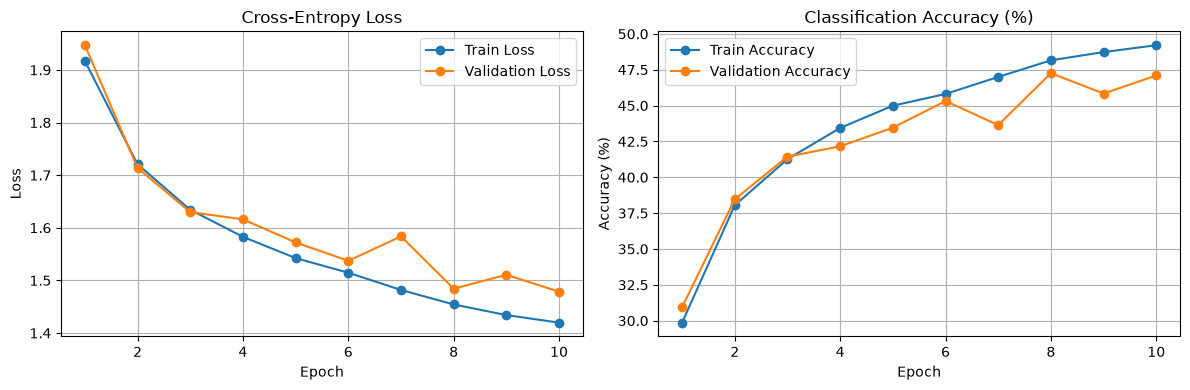


CIFAR-10 Experiment Results:
NeuralNetwork(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
Best Validation Loss: 1.4785 | Best Validation Accuracy: 47.10%
Test Loss: 1.4666 | Test Accuracy: 47.59%


In [13]:
params_cifar = {
    # Model and architecture
    "model_type": "MLP",          # "MLP" or "CNN"
    "in_channels": 3,             # 3 RGB channels for CIFAR-10
    "image_size": 32,             # 32x32 image size for CIFAR-10
    "hidden_dims": [128, 64], 
    "cnn_channels": [32, 64],     # Increased channels for 3-channel input
    "kernel_size": 3,
    "pool_size": 2,
    "stride": 2,

    # Activation & Initialization
    "activation": nn.ReLU, 
    "initialization": None,

    # Optimizer
    "optimizer": "SGD",
    "learning_rate": 0.01, 
    "weight_decay": 1e-4,
    "momentum": 0.9,

    # Regularization & Training
    "dropout": 0.0,
    "epochs": 10,
    "batch_size": 64
}

# Run experiment passing CIFAR datasets
model_cifar, history_cifar, best_val_loss_cifar, best_val_acc_cifar, test_loss_cifar, test_acc_cifar = run_experiment(
    params_cifar, 
    train=cifar_train, 
    validation=cifar_validation, 
    test=cifar_test, 
    plotting=True
)

print("\nCIFAR-10 Experiment Results:")
print(model_cifar)
print(f"Best Validation Loss: {best_val_loss_cifar:.4f} | Best Validation Accuracy: {best_val_acc_cifar:.2f}%")
print(f"Test Loss: {test_loss_cifar:.4f} | Test Accuracy: {test_acc_cifar:.2f}%")

# Task 2

## Telling the Time Neural Network

### Pre-processing

**Loading data: train, validation and test**

In [37]:
clock_images = np.load("data/A1_data_75/images.npy")   # expected (18000, 75, 75): 18000 images of size 75x75
clock_labels = np.load("data/A1_data_75/labels.npy")   # expected (18000, 2): 18000 labels of hour and minute pairs

x = torch.from_numpy(clock_images).float().unsqueeze(1) # converts pixels from unit8 to float and adds a channel dimension (1 because grayscale)
if x.max().item() > 1.0:                                # If pixel values are in range [0, 255], we scale them to [0, 1] for better training stability
    x = x / 255.0

y = torch.from_numpy(clock_labels).long()              # (18000, 2): 18000 labels of hour and minute pairs as tensor

clock_all = TensorDataset(x, y) # Create a TensorDataset from the images and labels

# Splitting the full data set into an 80/10/10 split for training/validation/test in one run. Random_split shuffles the data to fix any ordering in files
n = len(clock_all)
n_train = int(0.8 * n)
n_val = int(0.1 * n)
n_test = n - n_train - n_val

clock_train, clock_validation, clock_test = random_split(
    clock_all,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(420)
)


**Visualizing**

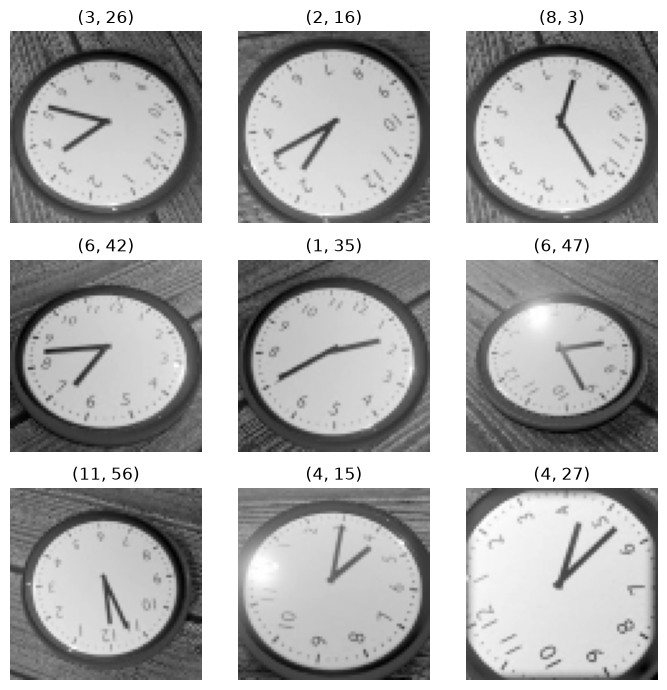

In [ ]:
idxs = torch.randperm(len(x))[:9]   # 9 random images

fig, ax = plt.subplots(3, 3, figsize=(7, 7))
for k, idx in enumerate(idxs): # idx is the actual clock/label pair we visualize, k is the index of the subplots we are fitting in the 3x3
    hour, minute = y[idx].tolist()
    ax[k // 3, k % 3].imshow(x[idx, 0], cmap="gray") # k// 3 and k %3 to properly index the 3x3 grid of subplots
    ax[k // 3, k % 3].axis("off")
    ax[k // 3, k % 3].set_title(f"({hour}, {minute})")
plt.tight_layout()
plt.show()

**Dataloader**

We again create the dataloaders. Shuffling is set to true for the training set again to make sure that the batches are random between epochs. For validation and test set since we take the average the order doesn't matter and as such we don't need to shuffle. 

We take the same batch size of Task 1. With 14,400 training images this amounts to 225 updates per epoch. 
We keep the batch size to a moderate 64 to account for the fact that the images, especially in the final run are much larger compared to task 1 (150x150 as opposed to 28x28) and as such take up more space in the memory.

In [46]:
batch_size = 64

clock_train_loader = DataLoader(clock_train, batch_size = batch_size, shuffle = True)
clock_validation_loader = DataLoader(clock_validation, batch_size = batch_size, shuffle = False)
clock_test_loader = DataLoader(clock_test, batch_size = batch_size, shuffle = False)

In [47]:
print(f"Number of batches in the training DataLoader: {len(clock_train_loader)}")
print(f"Number of batches in the validation DataLoader: {len(clock_validation_loader)}")
print(f"Number of batches in the test DataLoader: {len(clock_test_loader)}")
images, labels = next(iter(clock_train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Pixel range:", images.min().item(), images.max().item())

Number of batches in the training DataLoader: 225
Number of batches in the validation DataLoader: 29
Number of batches in the test DataLoader: 29
Image batch shape: torch.Size([64, 1, 75, 75])
Label batch shape: torch.Size([64, 2])
Image data type: torch.float32
Pixel range: 0.08235294371843338 1.0


### Model Building